# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Refuerzo, Paul Adam
- _Student No._: 2024-09465
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![1](integ.png)
**Figure 1.** Absolute Error of Integration Methods

![2](montecarlo.png)
**Figure 2.** Visualization of Monte-Carlo Method

### Report discussion

Figure 1 shows that the deterministic Newton-Cotes methods (Trapezoidal and Simpson's rules) rapidly converge with steep, monotonic error reduction as n increases, with Simpson's rules outperforming the Trapezoidal method. In contrast, the Monte Carlo method exhibits a much slower, fluctuating convergence rate, showing that random sampling is less efficient than deterministic grid partitioning for the given smooth 1D functions.

Figure 2 visualizes the Monte Carlo integration logic by uniformly sampling the bounding box and classifying points relative to the curve and the x-axis.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
# TEST FUNCTIONS
def f_1(x):
    return np.sqrt(9 - 4*x**2)

def f_2(x):
    return - x**2 + 1

def f_3(x):
    return np.sqrt(x)*np.cos(x)

In [3]:
# INTEGRATION METHODS
def trapezoidal(f, a, b, n=1000):
    h = (b - a)/n
    xs = np.linspace(a, b, n + 1)
    fs = f(xs)
    return (h / 2) * (fs[0] + 2 * np.sum(fs[1:-1]) + fs[-1])

def simpson_13(f, a, b, n=1000):
    if n % 2 != 0:
        raise ValueError('n must be even.')
    h = (b - a) / n
    xs = np.linspace(a, b, n + 1)
    fs = f(xs)
    return (h / 3) * (fs[0] + 4 * np.sum(fs[1:-1:2]) + 2 * np.sum(fs[2:-2:2]) + fs[-1])

def simpson_38(f, a, b, n=900):
    if n % 3 != 0:
        raise ValueError('n must be a multiple of 3.')
    h = (b - a) / n
    xs = np.linspace(a, b, n + 1)
    fs = f(xs)
    return (3 * h / 8) * (fs[0] + 3 * np.sum(fs[1:-1]) - np.sum(fs[3:-3:3]) + fs[-1])

def monte_carlo(f, a, b, n=1000, seed=None):
    rng = np.random.default_rng(seed)
    xs = rng.uniform(a, b, n)
    return (b - a) * np.mean(f(xs))

For f(x) = sqrt(9 - 4x^2):
 Signed Area (Quad): 3.534292
 Total Area  (Quad): 3.534292

For f(x) = -x^2 + 1:
 Signed Area (Quad): -1.333333
 Total Area  (Quad): 4.000000

For f(x) = sqrt(x)*cos(x):
 Signed Area (Quad): -0.894831
 Total Area  (Quad): 2.302907



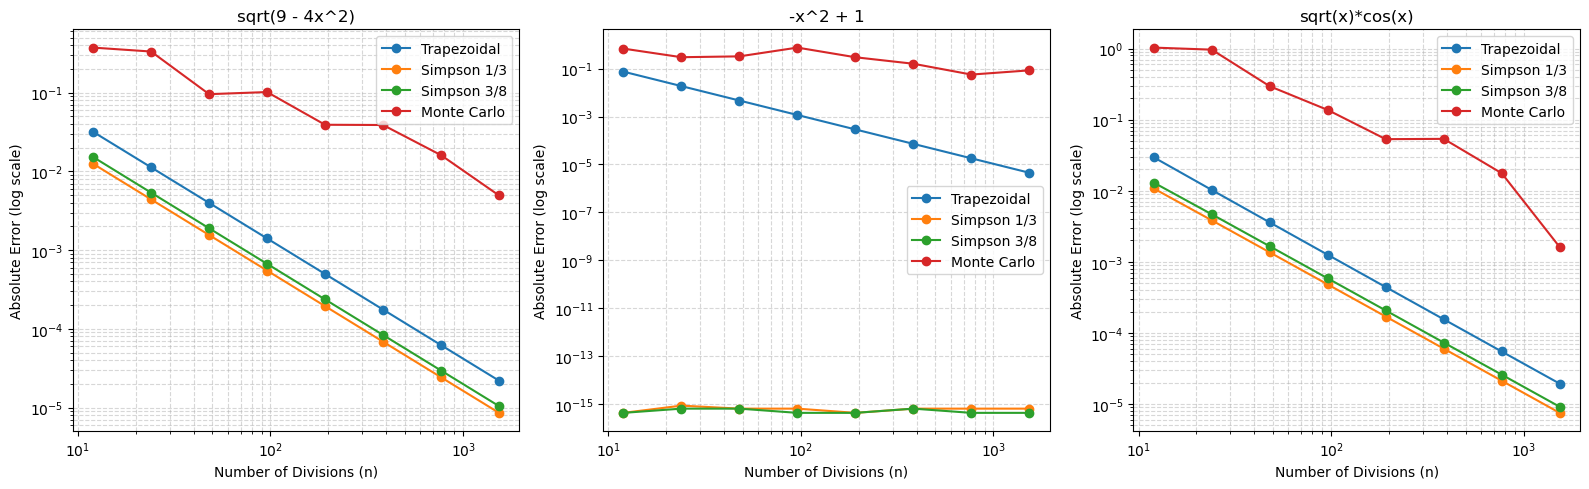

In [4]:
# TESTING METHODS ON FUNCTIONS
test_cases = [
    {'name': 'sqrt(9 - 4x^2)', 'f': f_1, 'a': 0, 'b': 3/2},
    {'name': '-x^2 + 1', 'f': f_2, 'a': -2, 'b': 2},
    {'name': 'sqrt(x)*cos(x)', 'f': f_3, 'a': 0, 'b': np.pi}
]

methods = [
    ('Trapezoidal', lambda f, a, b, n: trapezoidal(f, a, b, n)),
    ('Simpson 1/3', lambda f, a, b, n: simpson_13(f, a, b, n)),
    ('Simpson 3/8', lambda f, a, b, n: simpson_38(f, a, b, n)),
    ('Monte Carlo', lambda f, a, b, n: monte_carlo(f, a, b, n, seed=42))
]

# Number of intervals for convergence analysis (multiple of 6 to satisfy all methods)
ns = np.array([12, 24, 48, 96, 192, 384, 768, 1536])

fig, axs = plt.subplots(1, 3, figsize=(16, 5))

for i, case in enumerate(test_cases):
    f, a, b = case['f'], case['a'], case['b']
    
    signed_ref, _ = quad(f, a, b)
    total_ref, _  = quad(lambda x: np.abs(f(x)), a, b)
    
    print(f"For f(x) = {case['name']}:")
    print(f" Signed Area (Quad): {signed_ref:.6f}")
    print(f" Total Area  (Quad): {total_ref:.6f}\n")
    
    for name, method in methods:
        errors = []
        for n in ns:
            val = method(f, a, b, n)
            errors.append(np.abs(val - signed_ref))
        axs[i].loglog(ns, errors, marker='o', label=name)
        
    axs[i].set_title(case['name'])
    axs[i].set_xlabel('Number of Divisions (n)')
    axs[i].set_ylabel('Absolute Error (log scale)')
    axs[i].legend()
    axs[i].grid(True, which='both', ls='--', alpha=0.5)

fig.tight_layout()
fig.savefig('integ', dpi=300)
fig.show()

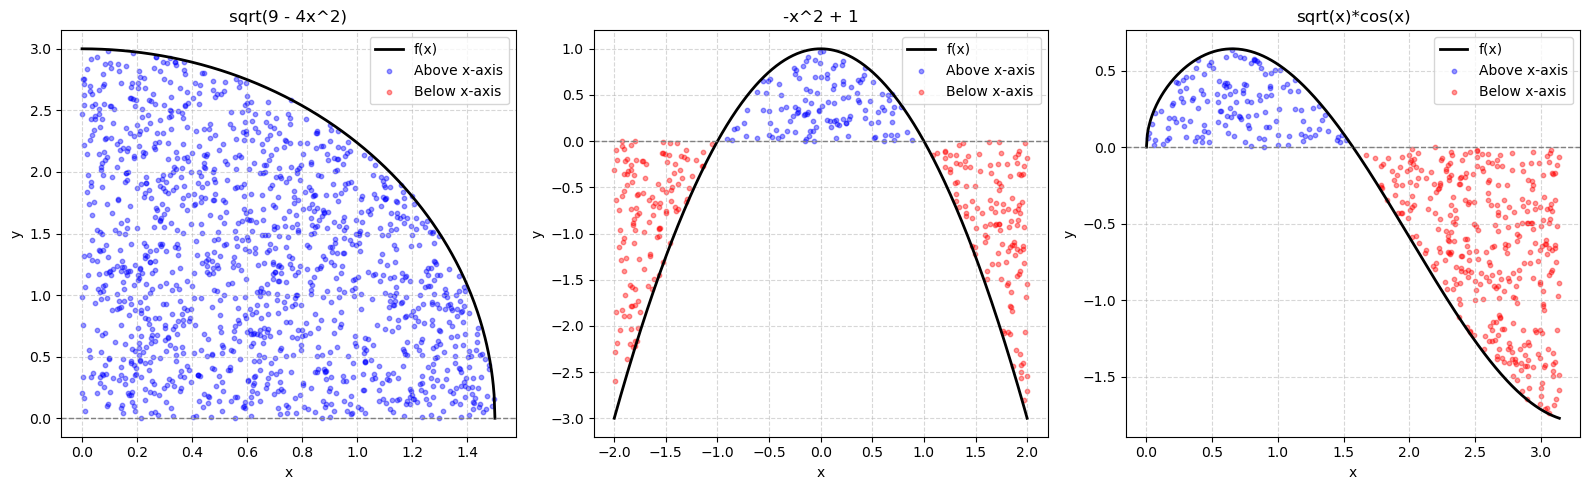

In [5]:
# MONTE CARLO VISUALIZATION
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

for i, case in enumerate(test_cases):
    f, a, b = case['f'], case['a'], case['b']
    rng = np.random.default_rng(42)
    
    x_rand = rng.uniform(a, b, 2000)
    x_vals = np.linspace(a, b, 500)
    y_vals = f(x_vals)
    y_rand = rng.uniform(min(0, y_vals.min()) * 1.2, y_vals.max() * 1.2, 2000)
    
    blue = (y_rand >= 0) & (y_rand <= f(x_rand))
    red = (y_rand < 0) & (y_rand >= f(x_rand))
    
    axs[i].plot(x_vals, y_vals, 'k-', lw=2, label='f(x)')
    axs[i].axhline(0, color='gray', ls='--', lw=1)
    axs[i].scatter(x_rand[blue], y_rand[blue], color='blue', alpha=0.4, s=10, label='Above x-axis')
    axs[i].scatter(x_rand[red], y_rand[red], color='red', alpha=0.4, s=10, label='Below x-axis')
    
    axs[i].set_title(case['name'])
    axs[i].set_xlabel('x')
    axs[i].set_ylabel('y')
    axs[i].legend(loc='upper right')
    axs[i].grid(ls='--', alpha=0.5)

fig.tight_layout()
fig.savefig('montecarlo', dpi=300)
fig.show()

#### Problem code summary

The above code implements different standard 1D numerical integration algorithms to compute signed and absolute areas for continuous test functions. It validates numerical accuracy against scipy.integrate.quad by calculating relative absolute errors across increasing grid divisions (n) on log-log convergence plots. Additionally, it provides visual spatial classification of Monte Carlo sample points bounded above and below the x-axis using color-coded scatter plots.